### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 6
### Due: Wed. Nov 4, at 11.59pm CT
---

This problem has to do with density estimation and clustering. 

1. Read in `hw6_data_1.npy`. The dataset should consist of $1000$ samples with $2$ features. Note that the last column are the labels, not another feature. Make a $2$-D scatter plot of the data colored by their labels. 


2. Start with kernel density estimation on the data set. First, perform a grid search $5$-fold cross-validation to find the best bandwidth, testing $30$ bandwidths between $0.1$ and $1.0$. What is this best bandwidth? Using this best bandwidth, plot the two-dimensional kernel density estimate of the distribution. 


3. Now try a nearest neighbors approach to estimating the density. Use the Bayesian nearest neighbors option. Plot the estimated distribution. What value of $k$ neighbors do you need to make the plot look similar to your KDE distribution?


4. Now fit a Gaussian mixture model. Compute the AIC and BIC for the number of GMM components between $1$ and $10$. Plot these AIC and BIC values as a function of number of components. What is the optimal number according to the BIC? Fit the data set with this optimal number of GMM components, and create a new plot that shows the data set, the GMM component mean locations, and the $2$-sigma GMM component ellipses. *(Use the code below to help with plotting the ellipses.)*

In [1]:
# Kludge to fix the bug with draw_ellipse in astroML
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                          (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                          width=2 * scale * sigma1, height=2 * scale * sigma2,
                          angle=alpha * 180. / np.pi,
                          **kwargs))

5. Now try Kmeans clustering with $5$ clusters. 
    - Use the `StandardScalar` to scale the data.
    - Fit the Kmeans model.
    - Find the cluster centers, and then inverse transform thse cluster centers back to the original unscaled coordinates.
    - Predict the labels for the scaled data.
    - Finally, make a two-panel side by side plot showing (a) the original data colored by its labels, then (b) the data colored by the Kmeans predicted labels, with cluster centers superposed.

### Solution

(1000, 3)


Text(0.5, 0, 'Feature 1')

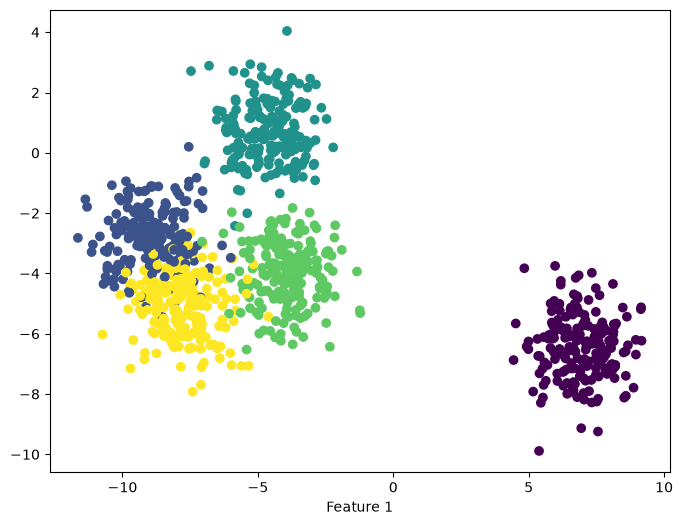

In [3]:
import numpy as np
import matplotlib.pyplot as plt

#load data
data = np.load('../../../homeworks/hw_data/hw6_data_1.npy')

#seperate features & labels
X = data[:, :2]
labels = data[:, 2]
print(data.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.xlabel('Feature 1')

In [5]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

bwrange = np.linspace(0.1, 1.0, 30)
K = 5

grid = GridSearchCV(KernelDensity(), {'bandwidth': bwrange}, cv=K)
grid.fit(X)

h_opt = grid.best_params_['bandwidth']
print(h_opt)

0.4724137931034482


<function matplotlib.pyplot.show(close=None, block=None)>

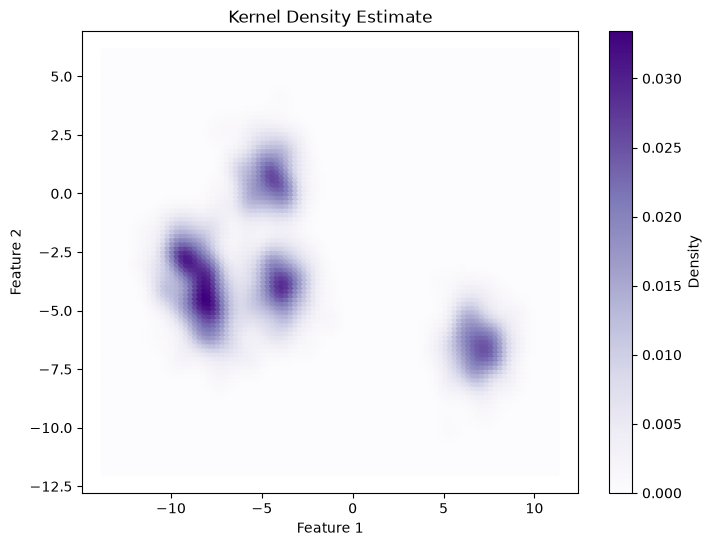

In [10]:
#KDE fit using bandwidth
kde = KernelDensity(bandwidth=h_opt, kernel='gaussian')
kde.fit(X)

#Grid
u = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 100)
v = np.linspace(X[:, 1].min() - 2, X[:, 1].max() + 2, 100)

Xgrid = np.vstack(list(map(np.ravel, np.meshgrid(u, v)))).T

#KDE Evaluation
dens = np.exp(kde.score_samples(Xgrid))

#plot
plt.figure(figsize=(8, 6))
plt.scatter(Xgrid[:, 0], Xgrid[:, 1], c=dens,
            cmap="Purples", edgecolor="none")
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Kernel Density Estimate')
plt.colorbar(label='Density')
plt.show

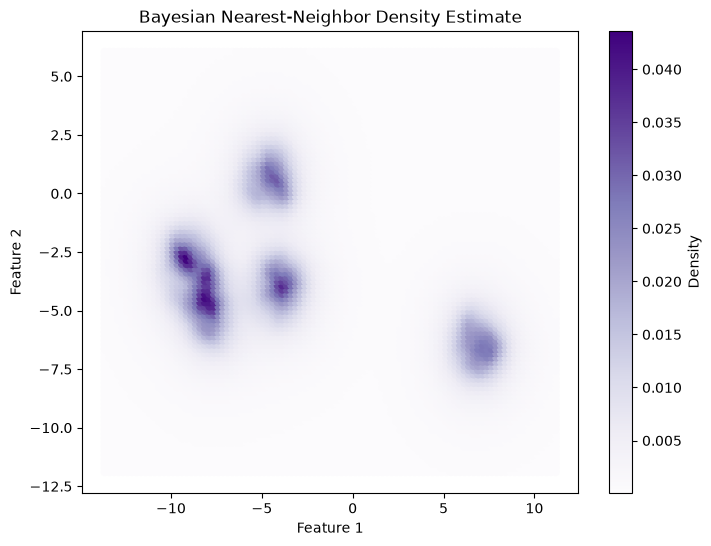

In [13]:
from astroML.density_estimation import KNeighborsDensity

#compute density
k = 50
nbrs = KNeighborsDensity('bayesian', n_neighbors=k)
nbrs.fit(X)

dens_nbrs = nbrs.eval(Xgrid)/len(X)

#density plot
plt.figure(figsize=(8, 6))
plt.scatter(Xgrid[:, 0], Xgrid[:, 1], c =dens_nbrs,
            cmap="Purples", edgecolor="none")
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Bayesian Nearest-Neighbor Density Estimate')
plt.colorbar(label='Density')
plt.show()

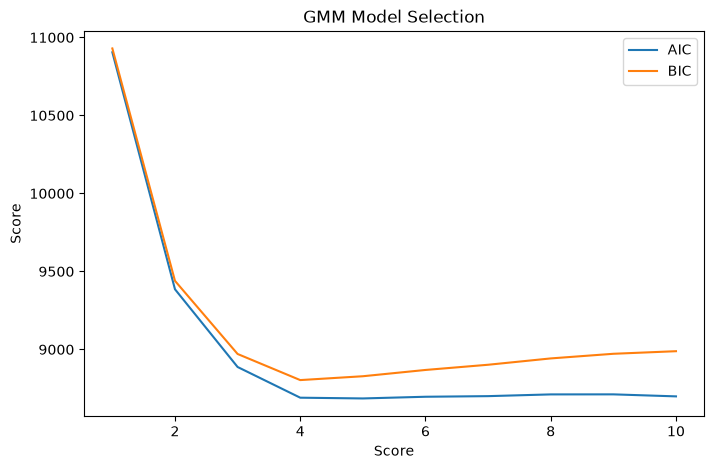

In [22]:
from sklearn.mixture import GaussianMixture

N = np.arange(1, 11)
models = [None for i in range(len(N))]

for i in range(len(N)):
    models[i] = GaussianMixture(N[i]).fit(X)

# AIC/BIC
AIC = [m.aic(X) for m in models]
BIC = [m.bic(X) for m in models]

plt.figure(figsize=(8, 5))
plt.plot(N, AIC, label='AIC')
plt.plot(N, BIC, label='BIC')
plt.xlabel('Score')
plt.ylabel('Score')
plt.title('GMM Model Selection')
plt.legend()
plt.show()